### **Estudo de Reconstrução 3D.**
Este notebook tem por objetivo estudar e registrar ferramentas e fórmulas teóricas para cálculo da profundidade estimada de cada pixel para reconstrução 3d.

In [351]:
# Bibliotecas.
from utils.alignment import load_images
from scipy.ndimage import convolve
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import cv2 as cv

In [352]:
# Função de Apoio - Visualização;
def show(array):
    pos_color = np.array([0.36, 0.82, 0.8])
    neg_color = np.array([0.99, 0.18, 0.13])
    array = np.array(array)
    pos = np.maximum(array, 0)[..., np.newaxis]
    neg = np.maximum(-array, 0)[..., np.newaxis]
    colored = pos * pos_color + neg * neg_color
    normalized = colored / np.max(np.abs(array))
    
    img = Image.fromarray((normalized * 255).astype(np.uint8))
    return(img)

In [353]:
# Imagens Alinhadas.
images = load_images("../src/images/boxes")
ref = cv.cvtColor(images[0], cv.COLOR_BGR2GRAY)


Fase 1.1: Ordenação.
Ordem de carregamento detectada: ['01.png', '02.png', '03.png'] ...


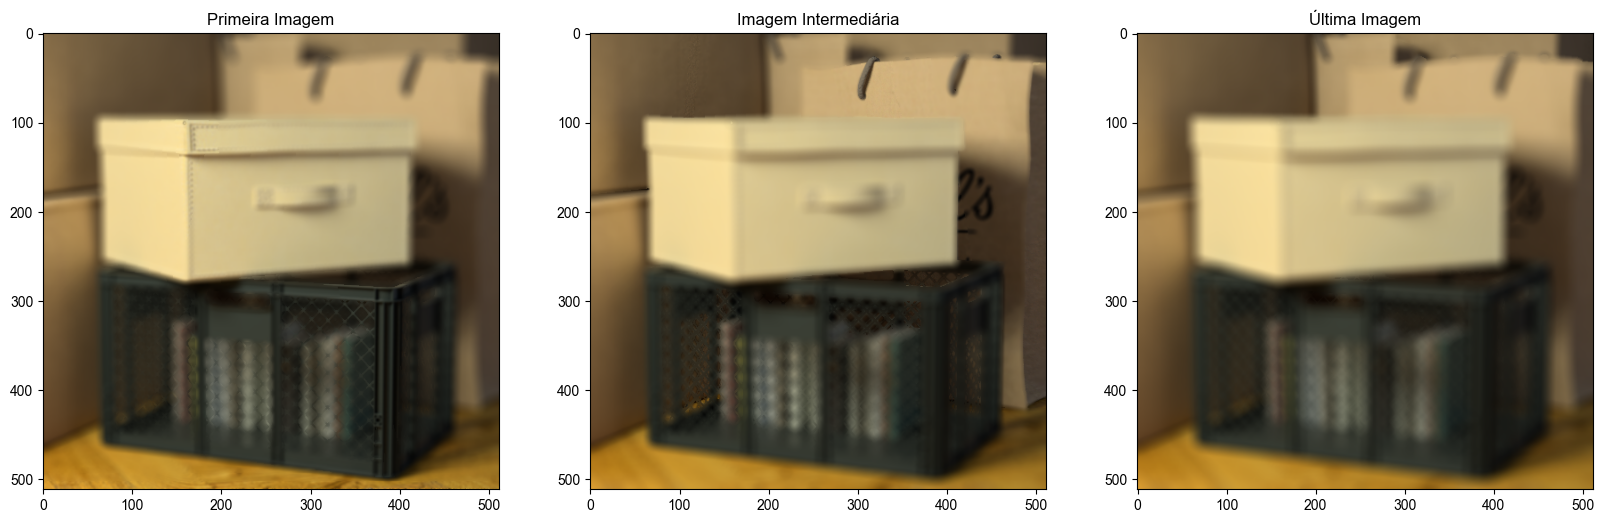

In [354]:
# Visualização das Imagens.
n = len(images)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 10))
ax1.imshow(cv.cvtColor(images[0], cv.COLOR_BGR2RGB), cmap='jet')
ax2.imshow(cv.cvtColor(images[n//2], cv.COLOR_BGR2RGB), cmap='jet')
ax3.imshow(cv.cvtColor(images[-1], cv.COLOR_BGR2RGB), cmap='jet')

ax1.set_title("Primeira Imagem")
ax2.set_title("Imagem Intermediária")
ax3.set_title("Última Imagem")

plt.show()

Uma vez que as imagens estão alinhadas, podemos avaliar as derivadas das imagens, utilizando o filtro de Sobel.

In [355]:
# Função de Apoio - Filtro de Sobel.
def edgeness(img):
    Sx = np.array([[-1, 0, 1],
                   [-2, 0, 2],
                   [-1, 0, 1]]) / 8
    Sy = Sx.T

    if img.ndim == 3:
        b = cv.cvtColor(img, cv.COLOR_BGR2GRAY) / 255.0
    else:
        b = img / 255.0

    grad_x = convolve(b, Sx)
    grad_y = convolve(b, Sy)

    return np.sqrt(grad_x**2 + grad_y**2)

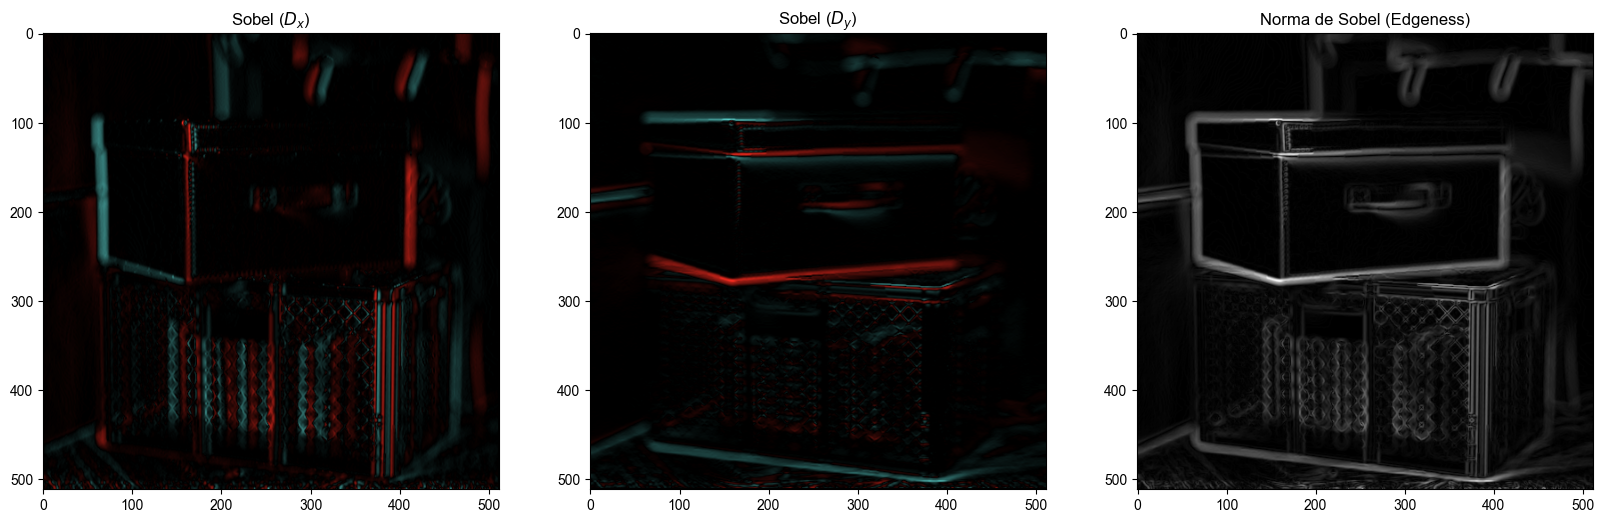

In [356]:
# Visualização Gráfica do Filtro de Sobel e Edgeness.

dx = cv.Sobel(src=ref, ddepth=cv.CV_64F, dx=1, dy=0)
dy = cv.Sobel(src=ref, ddepth=cv.CV_64F, dx=0, dy=1)

# Visualização das Imagens.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 10))
ax1.imshow(show(dx))
ax2.imshow(show(dy))
ax3.imshow(edgeness(ref), cmap='gray')

ax1.set_title("Sobel ($D_{x}$)")
ax2.set_title("Sobel ($D_{y}$)")
ax3.set_title("Norma de Sobel (Edgeness)")

plt.show()

Agora, vamos avaliar o laplaciano das imagens de referência $i_{0}$ e $i_{20}$, a fim de detectar os pontos de foco. 

**Obs:** Como nas camadas de foco, a frequência de nitidez gerada pelo Laplaciano é alta, observamos os resultados de duas maneiras: **com e sem filtro passa-baixa.**

In [357]:
# Função de Apoio - Laplaciano
def laplacian(img):
    L = np.array([[1,  1, 1],
                  [1, -8, 1],
                  [1,  1, 1]])

    if img.ndim == 3:
        b = cv.cvtColor(img, cv.COLOR_BGR2GRAY) / 255.0
    else:
        b = img / 255.0

    return convolve(b, L)

In [358]:
# Função de Apoio - Blur Gaussiano
def gaussian_blur(img):
    gauss = cv.GaussianBlur(img, (5, 5), 0)
    return gauss

In [359]:
# Função de Apoio - Maginitude de Nitidez
def focus(img, blur = 0):
    
    L = laplacian(img) 

    if blur:
        L = gaussian_blur(L)

    magnitude = np.absolute(L)

    return np.uint8(magnitude * 255)

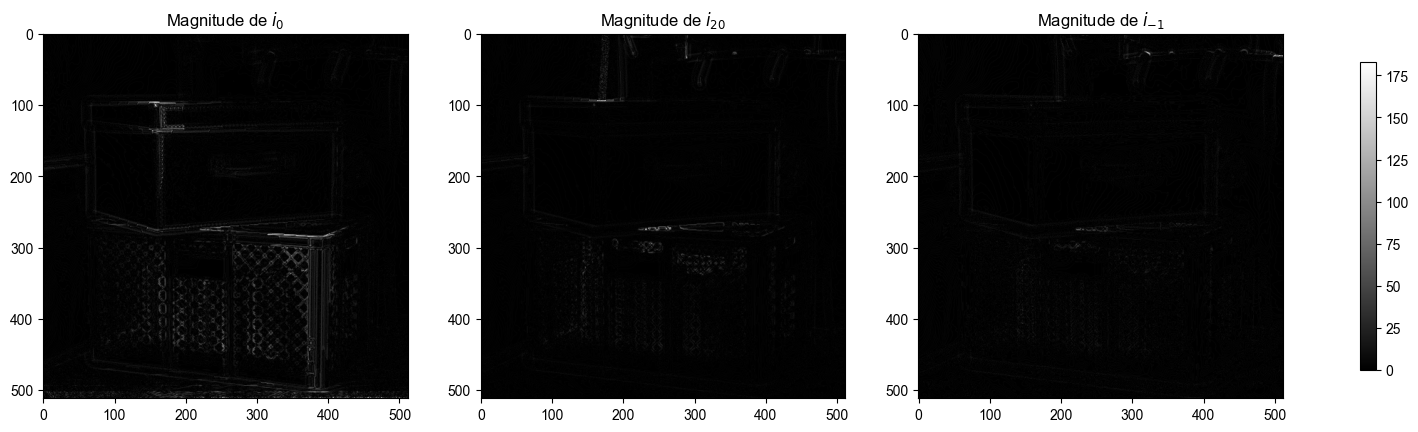

In [360]:
# Visualização das Imagens - Sem Filtro.
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
im = axs[0].imshow(focus(ref), cmap="gray")
axs[1].imshow(focus(images[20]), cmap="gray")
axs[2].imshow(focus(images[-1]), cmap="gray")

axs[0].set_title("Magnitude de $i_{0}$")
axs[1].set_title("Magnitude de $i_{20}$")
axs[2].set_title("Magnitude de $i_{-1}$")

fig.colorbar(im, ax=axs.tolist(), shrink=0.8)

plt.show()

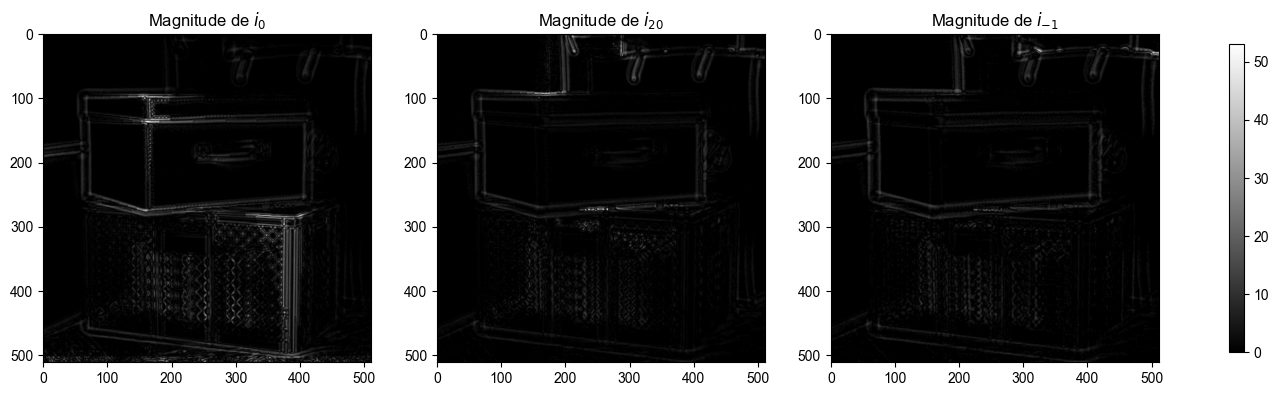

In [361]:
# Visualização das Imagens - Com Filtro.
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
im = axs[0].imshow(focus(ref, 1), cmap="gray")
axs[1].imshow(focus(images[20], 1), cmap="gray")
axs[2].imshow(focus(images[-1], 1), cmap="gray")

axs[0].set_title("Magnitude de $i_{0}$")
axs[1].set_title("Magnitude de $i_{20}$")
axs[2].set_title("Magnitude de $i_{-1}$")

fig.colorbar(im, ax=axs.tolist(), shrink=0.8)

plt.show()

Com as funções auxiliares em mãos, podemos construir a função que vai estimar a profundidade de cada pixel, com base no Volume de Nitidez da pilha de imagens.

In [362]:
# Função de Apoio - Mapa de Profundidade
def depth(images):
    """
    Realiza o Depth from Focus (DfF) para gerar a imagem nítida e mapas de dados.
    
    Parâmetros:
      images: Lista de imagens (numpy arrays) alinhadas.

    Retorna:
      Um dicionário com:
      - 'image': Imagem final.
      - 'depth_map': Mapa de índices.
      - 'confidence_map': Mapa de nitidez.
    """

    h, w = images[0].shape[:2]
    n = len(images)
    
    # 1. Alocação de Memória (Cubo de Nitidez)
    sharpness_cube = np.zeros((h, w, n), dtype=np.float32)
    
    # 2. Loop de Cálculo de Nitidez    
    for i, img in enumerate(images):
    
        ref = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
        L = focus(ref, blur=0)
        
        sharpness_cube[:, :, i] = L

    # 3. Seleção de Camada
    depth_index = np.argmax(sharpness_cube, axis=2)   # Mapa de Profundidade Bruto (Índices)
    confidence_map = np.max(sharpness_cube, axis=2)   # Mapa de Confiança (Valor da Magnitude)

    # 4. Reconstrução da Imagem  
    all_in_focus = np.zeros_like(images[0])    
    rows, cols = np.indices((h, w))
    
    stack_imgs = np.stack(images, axis=-1)     
    for c in range(3): 
        all_in_focus[:, :, c] = stack_imgs[:, :, c, :][rows, cols, depth_index]
    

    return {
        'image': all_in_focus,
        'depth_map': depth_index,
        'confidence': confidence_map
    }

In [363]:
results = depth(images)

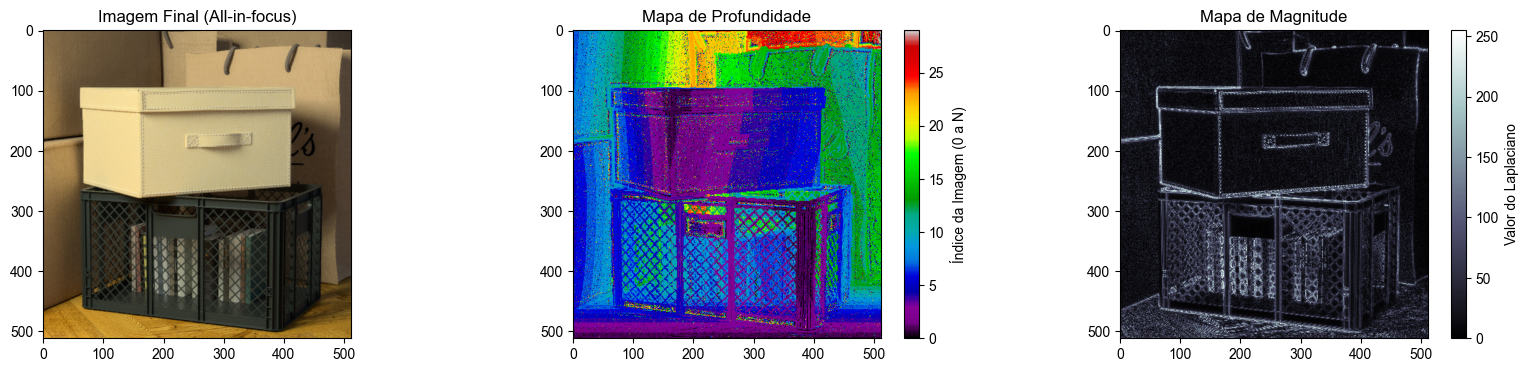

In [364]:
# Mapas de Profundidade

img = results['image']
depth = results['depth_map']
mag = results['confidence']

# Visualização das Imagens.
fig, axs = plt.subplots(1, 3, figsize=(20, 4))

axs[0].imshow(cv.cvtColor(results['image'], cv.COLOR_BGR2RGB), cmap='jet')

im1 = axs[1].imshow(depth, cmap='nipy_spectral')
fig.colorbar(im1, ax=axs[1], label='Índice da Imagem (0 a N)')

im2 = axs[2].imshow(mag, cmap='bone')
plt.colorbar(im2, ax=axs[2], label='Valor do Laplaciano')

axs[0].set_title("Imagem Final (All-in-focus)")
axs[1].set_title("Mapa de Profundidade")
axs[2].set_title("Mapa de Magnitude")

plt.show()

Graph Cut & Weighted Median Filter.

In [365]:
...

Ellipsis